# Q6. Noise source

In [1]:
import sys
sys.path.insert(0, '../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import metrics
import models
from data import CONDITIONS, ALL_CONDITIONS

W1117 16:27:06.667000 66558 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
COLORS = {'rf': 'tab:gray', 'cnn': 'tab:blue', 'resnet': 'tab:orange', 'wav2vec': 'tab:green'}
DATASETS = ['esc10', 'sc', 'sc_small']

WAV2VEC_ESC10 = True  # about 1 hour
WAV2VEC_SC = False  # about 1.5 hours
RUNS = (
    [('esc10', m) for m in models.MODELS if m != 'wav2vec' or WAV2VEC_ESC10]
    + [('sc_small', m) for m in models.MODELS]
    + [('sc', m) for m in models.MODELS if m != 'wav2vec' or WAV2VEC_SC]
)

In [3]:
def calib_table(d):
    return {c: metrics.evaluate(d[f'test_{c}'], d['y_test'], 1.0) for c in ALL_CONDITIONS}

for dataset, model in RUNS:
    print(dataset, model, flush=True)
    models.get_logits(dataset, model)
tables = {run: calib_table(models.get_logits(*run)) for run in RUNS}

esc10 rf


esc10 cnn


esc10 resnet


esc10 wav2vec


Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_hid.bias             | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (61 outputs left out)

sc_small wav2vec


sc rf


sc cnn


sc resnet


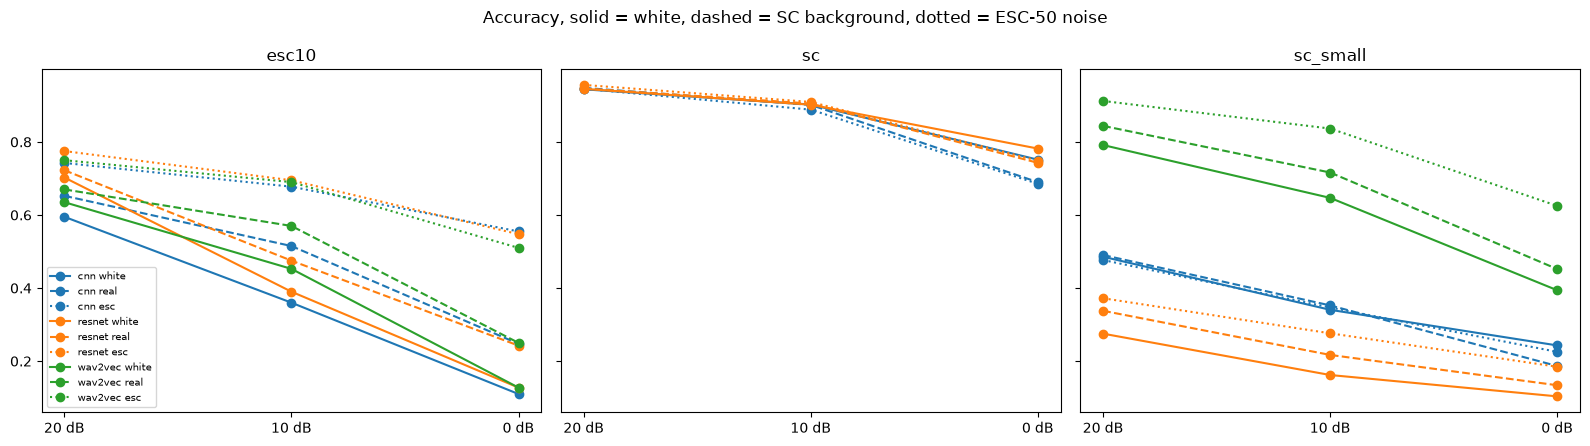

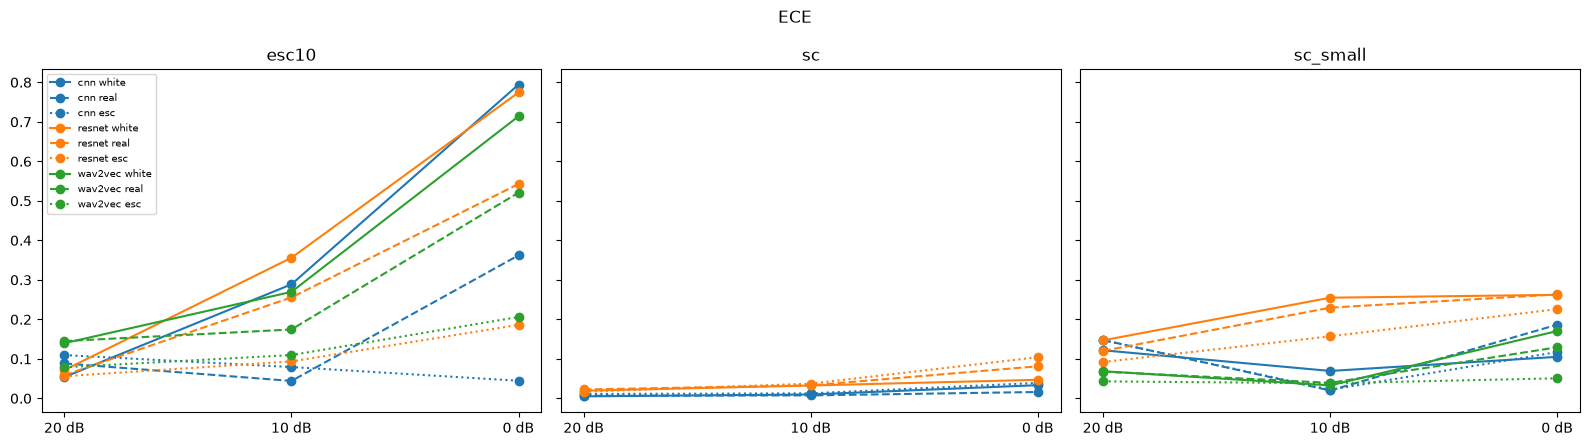

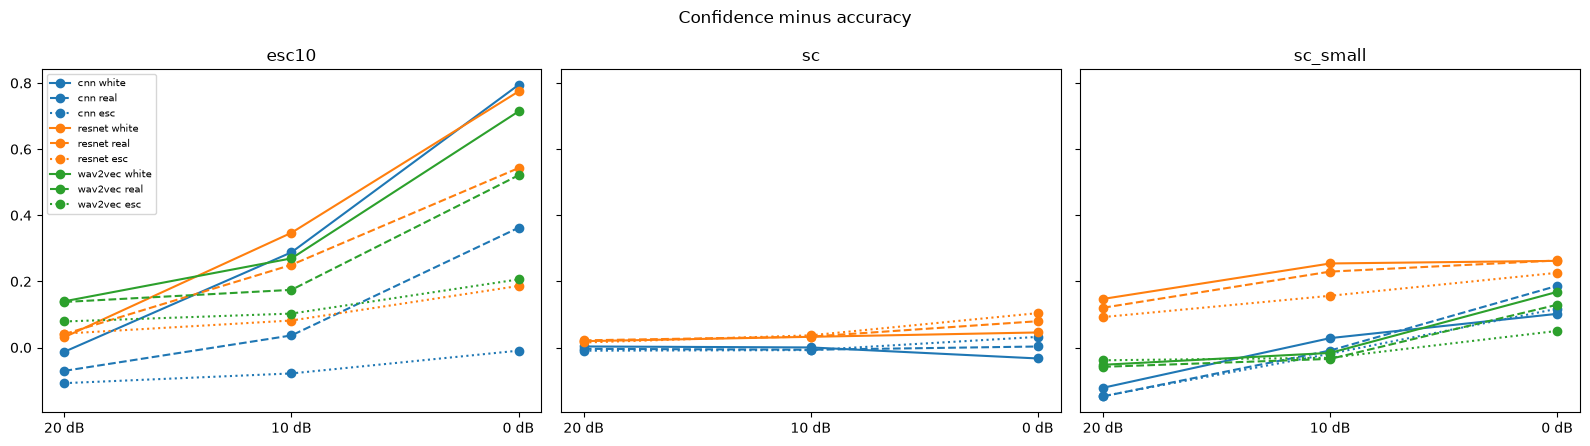

In [4]:
KINDS = {'white': '-', 'real': '--', 'esc': ':'}

def curves(metric, title):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
    for ax, dataset in zip(axes, DATASETS):
        for (d, model), table in tables.items():
            if d != dataset or model == 'rf':
                continue
            for kind, style in KINDS.items():
                values = [table[f'{kind}_{s}'][metric] for s in [20, 10, 0]]
                ax.plot(['20 dB', '10 dB', '0 dB'], values, style, marker='o', color=COLORS[model], label=f'{model} {kind}')
        ax.set_title(dataset)
    axes[0].legend(fontsize=7); fig.suptitle(title)
    plt.tight_layout(); fig.savefig('../results/figures/' + f'q6_{metric}' + '.png', dpi=150, bbox_inches='tight'); plt.show()

curves('acc', 'Accuracy, solid = white, dashed = SC background, dotted = ESC-50 noise')
curves('ece', 'ECE')
curves('overconf', 'Confidence minus accuracy')

In [5]:
rows = []
for (dataset, model), table in tables.items():
    for kind in KINDS:
        rows.append({'dataset': dataset, 'model': model, 'noise': kind, **table[f'{kind}_0']})
pd.DataFrame(rows).pivot_table(index=['dataset', 'model'], columns='noise', values=['acc', 'ece', 'overconf']).round(3)

acc                  ece               overconf         \
noise               esc   real  white    esc   real  white      esc   real   
dataset  model                                                               
esc10    cnn      0.555  0.248  0.110  0.045  0.362  0.794   -0.010  0.362   
         resnet   0.548  0.242  0.128  0.186  0.543  0.774    0.186  0.543   
         rf       0.468  0.232  0.170  0.133  0.144  0.268   -0.113  0.140   
         wav2vec  0.510  0.250  0.128  0.206  0.521  0.714    0.206  0.521   
sc       cnn      0.685  0.690  0.751  0.039  0.016  0.033    0.032  0.003   
         resnet   0.748  0.743  0.782  0.104  0.081  0.047    0.104  0.080   
         rf       0.242  0.206  0.171  0.028  0.032  0.041   -0.028 -0.032   
sc_small cnn      0.225  0.187  0.243  0.117  0.187  0.105    0.117  0.187   
         resnet   0.185  0.134  0.104  0.226  0.263  0.262    0.226  0.263   
         rf       0.191  0.162  0.126  0.006  0.018  0.062   -0.006  0.018   
         wav2vec  0.625  0.452  0.394  0.051  0.129  0.171    0.050  0.129   

                         
noise             white  
dataset  model           
esc10    cnn      0.794  
         resnet   0.774  
         rf       0.268  
         wav2vec  0.714  
sc       cnn     -0.033  
         resnet   0.046  
         rf       0.012  
sc_small cnn      0.102  
         resnet   0.262  
         rf       0.062  
         wav2vec  0.168

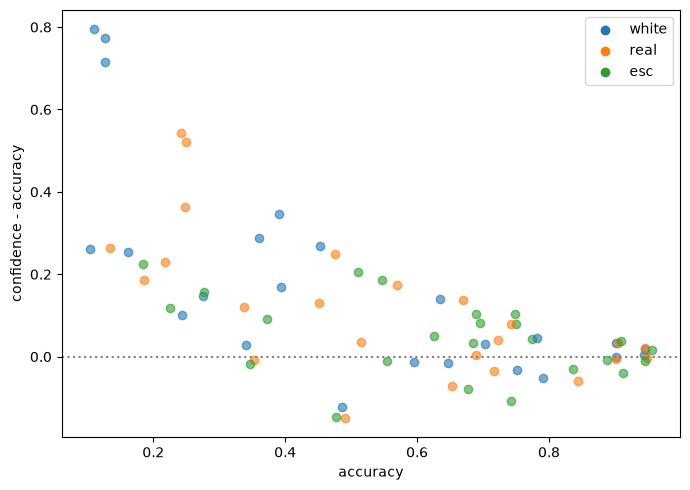

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
KIND_COLORS = {'white': 'tab:blue', 'real': 'tab:orange', 'esc': 'tab:green'}
for (dataset, model), table in tables.items():
    if model == 'rf':
        continue
    for kind in KINDS:
        for s in [20, 10, 0]:
            ax.scatter(table[f'{kind}_{s}']['acc'], table[f'{kind}_{s}']['overconf'], c=KIND_COLORS[kind], alpha=0.6)
for kind, color in KIND_COLORS.items():
    ax.scatter([], [], c=color, label=kind)
ax.axhline(0, color='gray', ls=':'); ax.set_xlabel('accuracy'); ax.set_ylabel('confidence - accuracy'); ax.legend()
plt.tight_layout(); fig.savefig('../results/figures/' + 'q6_noise_sources' + '.png', dpi=150, bbox_inches='tight'); plt.show()